# Income Differences Across Industries, Demographics, and Occupations / Senior Capstone Spring 2026

## Project Overview

### Research question
How much of the wage gap between Manufacturing, Finance, Information,
and Healthcare reflects **who works in each industry** (education, occupation,
sex, race), and how much remains after accounting for those differences?

### Data
American Community Survey (ACS) microdata from IPUMS USA (2024).
Sample: full-time wage and salary workers aged 18–64, not enrolled in school,
in the four industries above (N = 270,135 after cleaning). All descriptive
statistics and WLS regressions use the ACS person weight (PERWT).
Raw data are not included in this repository (see README for how to reproduce
the extract).

### Approach
1. **Data cleaning and variable construction** (Sections 1–5)
2. **Descriptive statistics** (Section 6)
3. **Mincer-style wage regression**, OLS vs. WLS with robust standard errors (Section 7)
4. **Industry wage gap decomposition** (Section 8): raw vs. adjusted gaps,
   controls added block by block, order-averaged (Shapley-style) contributions,
   and a direct check of workforce composition
5. **Sensitivity** to the occupation classification (Appendix)

### Key findings
- Finance and Information appear to pay 31% and 37% more than Manufacturing.
  After adjusting for worker characteristics and occupation the gaps shrink to about 1% and 6%;
  education and occupation account for most of the difference.
- Healthcare appears to pay 11% less (about 6% excluding social assistance), but about 17% less after adjustment (about 14% excluding social assistance), because composition (more university graduates and health occupations) hides part of the gap.
- Race/ethnicity is associated with individual wages (adjusted: Black −17%, Hispanic −16% vs. White)
  but explains little of the gap *between* industries.
- The Healthcare result is the most sensitive to how occupations are grouped:
  about −17% with nine groups vs. about −5% with the four groups used in the group project (Appendix A).

Details and interpretation are in Section 8.3.

### Caveats
- **Descriptive, not causal.** All results are adjusted associations. The sample covers four industries only, not the whole U.S. labor market.
- **Annual wages and "full-time".** Full-time is defined by usual weekly hours (≥ 40) only. Weeks worked are not in the extract and INCWAGE is annual, so part-year workers may remain and show lower annual wages. The $1,000 wage floor (Section 6) is a pragmatic cut-off; I did not test other floors.
- **Top-coding.** INCWAGE is top-coded at state-specific thresholds (the sample maximum, $907,000, equals DC's). The highest wages are understated, which may slightly understate the Finance and Information gaps. I did not adjust for it.
- **Standard errors.** HC1 robust; household-clustered SEs are similar (Section 7.4). ACS replicate weights are not used, so the survey design is only approximated.
- **Occupation-adjusted gaps** compare workers within the same occupation group and exclude the part of the gap that comes from an industry's occupation mix (Section 8.1).

### Project context
This notebook started as a group project for a Senior Capstone course Spring 2026 at Georgia State University. In the original project, I was responsible for data cleaning and preparation (Sections 1–5), including merging the IPUMS extracts, filtering the sample, creating dummy variables, and building the industry, occupation, and demographic variables used in the analysis. However, the step of creating dummy variables is omitted in this notebook because the regression analyses in Section 7 use the `formula API` in `statsmodels`, which automatically converts categorical variables into dummy variables. The wage analysis in the original group project was done by other members of the team.

I added the analysis in Sections 6–8 later on my own. This includes the wage regression, coefficient plots, and the breakdown of the industry wage gap. I wanted to use the cleaned dataset to practice the type of applied econometric analysis it was originally prepared for, while also turning the notebook into a complete piece of work that I could include in my public portfolio.

# 0. Import packages


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
import re
import numpy as np
from itertools import combinations, permutations

# 1. Load and check the data

Load the data using Pandas and check that it has been loaded correctly

In [2]:
# Set this to the location of your IPUMS data
path_to_data = "./data/usa_00007.csv"

In [3]:
# Load the files
df = pd.read_csv(path_to_data)

# I am not allowed to show data from IPUMS
# df.head()

# 2. Filter Data

Since we are going to analyze income distribution across industries, 
we narrow down the data based on the following criteria:

1. **Age:** 18–64 years old (65 is typically considered the retirement age in the U.S.)
2. **School enrollment:** Not currently attending school (to focus on working-age individuals)
3. **Class of worker:** Wage or salary workers (to exclude self-employed individuals)
4. **Work hours:** At least 40 hours per week (to focus on full-time workers)
5. **Employment status:** Employed
6. **Income:** Greater than $0 (to exclude zero or negative income values)
7. **Income:** Exclude observations with INCWAGE codes of 999,998 (Missing) and 999,999 (N/A).


In [4]:
# EMPSTAT was string. So, change it to int
df['EMPSTAT'] = df['EMPSTAT'].astype(int)

# Age is 18 to 64. People should not attend school, employed, not own business (work for wages),
# People should be full time working (over 40 hours working a week), Income should be over 0 and less than 999998 (Missing value)
df_clean = df[
    (df['AGE'].between(18, 64)) & 
    (df['SCHOOL'] == 1) & 
    (df['CLASSWKR'] == 2) & 
    (df['UHRSWORK'] >= 40) & 
    (df['EMPSTAT'] == 1) &
    (df['INCWAGE'] > 0) & 
    ~(df['INCWAGE'].isin([999998, 999999]))
 ].copy() 

print(f"how many numbers left after filtering: {len(df_clean):,}")

# df_clean.head()

how many numbers left after filtering: 935,362


# 3. Classifying Industries and Occupations

1. For this Capstone Project, we classify workers into four industry categories:
   - Manufacturing
   - Information
   - Finance
   - Healthcare

2. Occupation classification
   - Professional Tech
   - Management Finance
   - Admin Support
   - Service_Others

3. I use IPUMS occupation and industry codes to classify individuals into these four categories.

**Note on the Healthcare definition.** "Healthcare" here is NAICS sector 62 (Health Care and Social Assistance). It includes social assistance (NAICS 624, e.g., child day care and individual and family services), which accounts for about 13% of Healthcare workers. Appendix A reports the adjusted gap excluding NAICS 624.

In [5]:
# Convert INDNAICS codes to strings and remove leading/trailing whitespace
# to prepare the codes for industry classification.
df_clean['Sector_Code_Str'] = df_clean['INDNAICS'].astype(str).str.strip()

df_clean['Target_Industry'] = None # create an empty column

df_clean.loc[df_clean['Sector_Code_Str'].str.startswith(('31', '32', '33')), 'Target_Industry'] = 'Manufacturing'
df_clean.loc[df_clean['Sector_Code_Str'].str.startswith('51'), 'Target_Industry'] = 'Information'
df_clean.loc[df_clean['Sector_Code_Str'].str.startswith('52'), 'Target_Industry'] = 'Finance'
df_clean.loc[df_clean['Sector_Code_Str'].str.startswith('62'), 'Target_Industry'] = 'Healthcare'

df_final_four = df_clean.dropna(subset=['Target_Industry']).copy()

# Count the number of observations
print(f"Classification complete! Remaining number of observations: {len(df_final_four):,}")
print(df_final_four['Target_Industry'].value_counts())


Classification complete! Remaining number of observations: 315,662
Target_Industry
Manufacturing    120367
Healthcare       117484
Finance           57830
Information       19981
Name: count, dtype: int64


In [6]:
def classify_occupation(occ_code):
    """
    Classify occupation codes into four broad job categories:
    Professional/Technical, Management/Finance, Admin/Support,
    or Service/Others.
    """
    occ = int(occ_code)
    
    # 1. Professional and technical occupations
    if 1005 <= occ <= 1980:
        return 'Professional_Tech'
    
    # 2. Management, business, and finance occupations
    elif 10 <= occ <= 960:
        return 'Management_Finance'
    
    # 3. Administrative and support occupations (e.g., receptionists)
    elif 5000 <= occ <= 5940:
        return 'Admin_Support'
    
    # 4. Everything else: service and blue-collar occupations, etc.
    else:
        return 'Service_Others'

# Cast the column to integer before applying the function
df_final_four['OCC_Group'] = df_final_four['OCC'].astype(int).apply(classify_occupation)

# Check the counts to confirm the classification worked as expected
print(df_final_four['OCC_Group'].value_counts())

OCC_Group
Service_Others        165587
Management_Finance     77455
Professional_Tech      36472
Admin_Support          36148
Name: count, dtype: int64


# 4. Create value labels

1. State
2. Marital Status
3. Race
4. Education
5. Sex
6. Metro area or Rural area


In [7]:
#  Create state names from STATEFIP codes

state_map = {
    1: 'AL', 2: 'AK', 4: 'AZ', 5: 'AR', 6: 'CA', 8: 'CO', 9: 'CT', 10: 'DE',
    11: 'DC', 12: 'FL', 13: 'GA', 15: 'HI', 16: 'ID', 17: 'IL', 18: 'IN',
    19: 'IA', 20: 'KS', 21: 'KY', 22: 'LA', 23: 'ME', 24: 'MD', 25: 'MA',
    26: 'MI', 27: 'MN', 28: 'MS', 29: 'MO', 30: 'MT', 31: 'NE', 32: 'NV',
    33: 'NH', 34: 'NJ', 35: 'NM', 36: 'NY', 37: 'NC', 38: 'ND', 39: 'OH',
    40: 'OK', 41: 'OR', 42: 'PA', 44: 'RI', 45: 'SC', 46: 'SD', 47: 'TN',
    48: 'TX', 49: 'UT', 50: 'VT', 51: 'VA', 53: 'WA', 54: 'WV', 55: 'WI', 56: 'WY'
}

df_final_four['State_Name'] = df_final_four['STATEFIP'].map(state_map)
print(df_final_four[['STATEFIP', 'State_Name']].drop_duplicates().sort_values('STATEFIP').head(20))

         STATEFIP State_Name
3800            1         AL
53714           2         AK
60920           4         AZ
136798          5         AR
168696          6         CA
563561          8         CO
625283          9         CT
663233         10         DE
673599         11         DC
679625         12         FL
892791         13         GA
1004551        15         HI
1019683        16         ID
1040751        17         IL
1171759        18         IN
1242780        19         IA
1276185        20         KS
1305073        21         KY
1353028        22         LA
1400113        23         ME


In [8]:
# Create marital status categories from MARST codes

def Marital_status(marst_code):
    marst = int(marst_code)
    
    if marst in [1, 2]:
        return 'Married'
    
    elif marst in [3, 4]:
        return 'Divorced_or_separated'
    
    elif marst == 5:
        return 'Widowed'
    
    else:
        return 'Never_Married'
    
df_final_four['Marital_Status'] = df_final_four['MARST'].astype(int).apply(Marital_status)


In [9]:
# Create race/ethnicity categories

def classify_race(row):
    # 1. First, determine whether the person is Hispanic
    if row['HISPAN'] in [1, 2, 3, 4]:
        return 'Hispanic'
    
    # 2. If not Hispanic, classify by RACE code
    r = int(row['RACE'])
    if r == 1:
        return 'White'
    elif r == 2:
        return 'Black'
    elif 4 <= r <= 6:
        return 'Asian'
    elif r == 3:
        return 'Indigenous' # Indigenous / Native American
    elif r in [8, 9]:
        return 'Mixed' # Mixed race
    else:
        return 'Other'

# Apply the classification
df_final_four['Race_Eth'] = df_final_four.apply(classify_race, axis=1)

# Drop rows classified as 'Other'
df_final_four = df_final_four[df_final_four['Race_Eth'] != 'Other'].copy()

# print(df_final_four.head())

# Confirm how many people (what percentage(%)) are in each group 
print("how many people are in each group (%):")
print(df_final_four['Race_Eth'].value_counts(normalize=True).round(3) * 100)

how many people are in each group (%):
Race_Eth
White         64.9
Hispanic      13.8
Asian          8.9
Black          8.0
Mixed          3.9
Indigenous     0.6
Name: proportion, dtype: float64


In [10]:
# Create education level categories

def education(educ_code):
    e = int(educ_code)
    if 0 <= e <= 5:          # 0 = N/A or no schooling
        return 'Below_HS'
    elif e == 6:
        return 'HS_Graduate'
    elif 7 <= e <= 9:
        return 'some_college'   # (some college / associate)
    elif 10 <= e <= 11:
        return 'University'
    else:
        raise ValueError(f"Unexpected EDUC code: {e}")
    
df_final_four['Education'] = df_final_four['EDUC'].apply(education)

In [11]:
# Create gender categories from SEX codes

def gender(sex_code):
    s = int(sex_code)
    if s == 1:
        return "Male"
    
    elif s == 2:
        return "Female"
    
df_final_four['Sex'] = df_final_four['SEX'].apply(gender)

In [12]:
# Based on the IPUMS USA code, we can determine the meaning of each value:
# 1	Not in metropolitan area
# 2	Metropolitan status indeterminable (mixed) in metropolitan area	
# 3	Not in central/principal city
# 4	Central/principal city status indeterminable (mixed)
# 5	In central/principal city

print(df_final_four["METRO"].value_counts())


METRO
4    108808
3     94681
2     44007
5     36236
1     30591
Name: count, dtype: int64


In [13]:
# I classify respondents into two groups: Metro vs. Rural.
# METRO = 1 is classified as "Rural," while METRO = 3, 4, or 5 is classified as "Metro."
# METRO = 2 is excluded because metropolitan status is indeterminable (mixed),
# so it cannot be reliably classified as either Metro or Rural.

# Drop observations whose metro status is indeterminable (METRO == 2)
n0 = len(df_final_four)
df_final_four = df_final_four[df_final_four['METRO'] != 2].copy()
print(f"Dropped METRO == 2: {n0 - len(df_final_four):,} ({(n0 - len(df_final_four))/n0*100:.1f}%)")

# If METRO = 1, assign 'Rural'; otherwise (3, 4, or 5), assign 'Metro'.
# Create a NEW column instead of overwriting METRO (safe to re-run)
df_final_four['Metro_Status'] = np.where(df_final_four['METRO'] == 1, 'Rural', 'Metro')

# Check the results
print(df_final_four['Metro_Status'].value_counts())



Dropped METRO == 2: 44,007 (14.0%)
Metro_Status
Metro    239725
Rural     30591
Name: count, dtype: int64


**Note on sample loss.** Dropping respondents whose metropolitan status is
indeterminable (METRO = 2) removes 44,007 observations, about 14% of the sample
at this step. Metro status is used only as a control, so I chose a clean
Metro/Rural definition over keeping these observations. These respondents are
not necessarily missing at random, so the results apply to respondents with a
determinable metro status. Dropping race/ethnicity "Other" (1,339 observations,
0.4%) is a smaller loss of the same kind.

# 5. Remove all columns that are not directly used in the analysis

1. Check columns
2. Remove all columns that are not needed anymore

In [14]:
df_final_four.columns.tolist()

['SERIAL',
 'STATEFIP',
 'METRO',
 'PERNUM',
 'PERWT',
 'SEX',
 'AGE',
 'MARST',
 'RACE',
 'RACED',
 'HISPAN',
 'HISPAND',
 'SCHOOL',
 'EDUC',
 'EDUCD',
 'EMPSTAT',
 'EMPSTATD',
 'CLASSWKR',
 'CLASSWKRD',
 'OCC',
 'IND',
 'INDNAICS',
 'UHRSWORK',
 'INCWAGE',
 'Sector_Code_Str',
 'Target_Industry',
 'OCC_Group',
 'State_Name',
 'Marital_Status',
 'Race_Eth',
 'Education',
 'Sex',
 'Metro_Status']

In [15]:
# Remove all columns that are not directly used in the analysis.
drop_cols = [
    'STATEFIP', 'INDNAICS', 
    'Sector_Code_Str', 'EMPSTATD', 
    'CLASSWKRD', 'SCHOOL', 'SEX',
    'EMPSTAT', 'EDUCD','EDUC',
    'CLASSWKR', 'UHRSWORK', 'IND', 
    'OCC', 'RACE', 
    'MARST', 'HISPAN', 'METRO'
    ]
df_final = df_final_four.drop(columns=drop_cols, errors='ignore')

print(f"Current number of samples: {len(df_final):,}")
print("Remaining columns:", df_final.columns.tolist())
# df_final.head()

Current number of samples: 270,316
Remaining columns: ['SERIAL', 'PERNUM', 'PERWT', 'AGE', 'RACED', 'HISPAND', 'INCWAGE', 'Target_Industry', 'OCC_Group', 'State_Name', 'Marital_Status', 'Race_Eth', 'Education', 'Sex', 'Metro_Status']


*Everything above this point (Sections 1–5) is data cleaning from the original group project. Everything below (Sections 6–8) is independent analysis I added afterward.*

# 6. Descriptive Statistics

Before looking at the regression results, this section describes the sample. It shows the distribution of wages and age and the composition of the sample for the categorical variables used in Sections 7–8.

All statistics are weighted by PERWT, so they better represent the population, not just the raw sample.

The wage histogram also helps explain a choice made in Section 7. INCWAGE is right-skewed, with a long tail of high earners. Because of this pattern, using a log transformation for the regression is appropriate.

### Note
**Wage floor (added during my analysis).**
 This step was **not** included in the original group work (Sections 1–5). I found this issue while doing my own descriptive analysis and regression in Sections 6–8.

I found 181 observations (0.067% of the cleaned sample) with INCWAGE below $1,000. The lowest value was $4, which is not realistic annual wage income for workers who meet our employment criteria.

Because the regression uses log(INCWAGE), these very low values can have an effect on the results even though there are only a few of them.

I did not change the original df_final dataset. Instead, I created a filtered copy called df_analysis and used it for all analysis from this point forward.

**The $1,000 threshold is a pragmatic cut-off, not a correction for part-year work (see Caveats).**

In [16]:
low_wage = df_final[df_final['INCWAGE'] < 1000]
print(f"INCWAGE < $1,000: {len(low_wage)} observations ({len(low_wage)/len(df_final)*100:.3f}% of sample)")
print(df_final['INCWAGE'].sort_values().head(10))

INCWAGE < $1,000: 181 observations (0.067% of sample)
3154927     4
479664     20
2331496    40
2328822    40
3060767    50
1386279    50
1925144    50
1960232    50
1597056    60
2010187    60
Name: INCWAGE, dtype: int64


In [17]:
wage_floor = 1000
df_analysis = df_final[df_final['INCWAGE'] >= wage_floor].copy()

# --- Finer occupation groups (added in my independent analysis; OCC_Group from Section 3 is kept as is) ---
df_analysis = df_analysis.join(df_final_four[['OCC']])
occ = df_analysis['OCC'].astype(int)

conditions = [
    occ.between(10, 960),    occ.between(1005, 1980), occ.between(2000, 2999),
    occ.between(3000, 3655), occ.between(3700, 4655), occ.between(4700, 4965),
    occ.between(5000, 5940), occ.between(6005, 7640), occ.between(7700, 9760),
]
labels = ['Mgmt_Business_Fin', 'STEM', 'Edu_Legal_Arts',
          'Health_Occ', 'Service_Protective', 'Sales',
          'Office_Admin', 'Construction_Maint', 'Production_Transport']
df_analysis['OCC_Fine'] = np.select(conditions, labels, default='Other')
assert (df_analysis['OCC_Fine'] == 'Other').sum() == 0   # 9 groups cover everyone (confirmed in the appendix run)
df_analysis = df_analysis.drop(columns='OCC')
print(df_analysis['OCC_Fine'].value_counts())

n_before, n_after = len(df_final), len(df_analysis)
print(f"Dropped {n_before - n_after} observations ({(n_before - n_after)/n_before*100:.3f}%) with INCWAGE < ${wage_floor}")
print(f"Analysis sample: {n_after:,}")

OCC_Fine
Mgmt_Business_Fin       69174
Health_Occ              53301
Production_Transport    40168
STEM                    33223
Office_Admin            30547
Edu_Legal_Arts          16322
Sales                   11711
Construction_Maint       8694
Service_Protective       6995
Name: count, dtype: int64
Dropped 181 observations (0.067%) with INCWAGE < $1000
Analysis sample: 270,135


## 6.1 Summary Statistics

               N  Weighted Mean  Weighted Median  Weighted SD   Min     Max
Variable                                                                   
AGE       270135           42.3               42         11.8    18      64
INCWAGE   270135        95085.0            68000      98294.8  1000  907000


,Variable,Category,Weighted %
0,Sex,Female,51.1
1,Sex,Male,48.9
2,Education,Below_HS,3.5
3,Education,HS_Graduate,27.0
4,Education,University,48.8
5,Education,some_college,20.7
6,Race_Eth,Asian,9.6
7,Race_Eth,Black,12.7
8,Race_Eth,Hispanic,17.4
9,Race_Eth,Indigenous,0.3


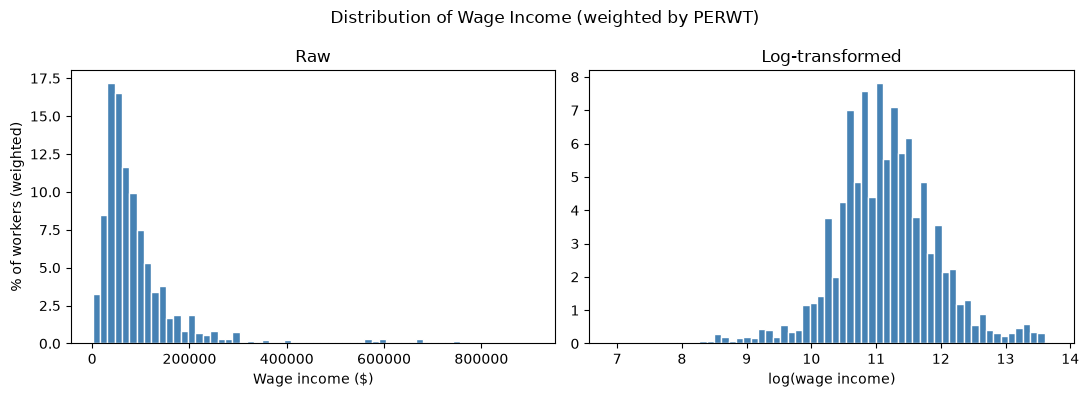

In [18]:
# --- Weighted summary statistics for continuous variables ---
def weighted_median(x, w):
    order = np.argsort(x)
    x, w = np.array(x)[order], np.array(w)[order]
    cum_w = np.cumsum(w)
    cutoff = cum_w[-1] / 2
    return x[np.searchsorted(cum_w, cutoff)]

def weighted_summary(df, cols, weight_col='PERWT'):
    rows = []
    for col in cols:
        x, w = df[col].values, df[weight_col].values
        mean = np.average(x, weights=w)
        std = np.sqrt(np.average((x - mean)**2, weights=w))
        rows.append({
            'Variable': col, 'N': len(x),
            'Weighted Mean': round(mean, 1),
            'Weighted Median': round(weighted_median(x, w), 1),
            'Weighted SD': round(std, 1),
            'Min': x.min(), 'Max': x.max(),
        })
    return pd.DataFrame(rows).set_index('Variable')

print(weighted_summary(df_analysis, ['AGE', 'INCWAGE']))

# --- Weighted frequency tables for categorical variables ---
def weighted_freq(df, col, weight_col='PERWT'):
    return (df.groupby(col)[weight_col].sum() / df[weight_col].sum() * 100).round(1)


# --- Combine the weighted frequency distributions of all categorical variables into one table. ---
freq_tables = []
for col in ['Sex', 'Education', 'Race_Eth', 'Marital_Status', 'Metro_Status', 'Target_Industry', 'OCC_Fine']:
    freq = weighted_freq(df_analysis, col).rename('Weighted %').reset_index()
    freq.insert(0, 'Variable', col)
    freq = freq.rename(columns={col: 'Category'})
    freq_tables.append(freq)

freq_summary = pd.concat(freq_tables, ignore_index=True)
display(freq_summary)  

# --- Wage distribution (weighted): raw vs. log ---
w = df_analysis['PERWT'] / df_analysis['PERWT'].sum() * 100   # share of weighted workforce (%)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df_analysis['INCWAGE'], bins=60, weights=w,
             color='steelblue', edgecolor='white')
axes[0].set_xlabel('Wage income ($)')
axes[0].set_ylabel('% of workers (weighted)')
axes[0].set_title('Raw')

axes[1].hist(np.log(df_analysis['INCWAGE']), bins=60, weights=w,
             color='steelblue', edgecolor='white')
axes[1].set_xlabel('log(wage income)')
axes[1].set_title('Log-transformed')

fig.suptitle('Distribution of Wage Income (weighted by PERWT)')
plt.tight_layout()
plt.show()

The average worker in this sample is 42.3 years old (median: 42) and earns $95,085 on average (median: $68,000). The large difference between the mean and median shows that the wage distribution is right-skewed. The standard deviation is also very large ($98,294). This supports the use of a log transformation of wages in Section 7.

There are two important points to remember when looking at the composition table:

**This sample does not represent all U.S. workers.** It represents workers in only four industries: Finance, Healthcare, Information, and Manufacturing. In this sample, 48.8% have a university degree and 91.8% live in a metro area. These numbers are higher than in the general U.S. population. This is not an error. These four industries have more highly educated and urban workers than industries not included in this analysis, such as retail, food service, construction, and agriculture.

The sample sizes are also different across groups. Information is the smallest of the four industries, with only 6.6% of the sample, while Healthcare and Manufacturing each make up 36–38%. Indigenous (0.3%) and Widowed (1.2%) are also very small groups. This helps explain why these groups have wider confidence intervals in Sections 7 and 8.

# 7. Wage regression: OLS vs. WLS

This section uses the cleaned sample from Sections 1–6 to estimate a Mincer-style wage regression. The goal is to examine how wages differ across industries, occupations, education levels, race, sex, and geographic areas while holding other characteristics constant.

**Reference (baseline) categories** I set a specific reference group for each categorical variable using Treatment(): Male, HS_Graduate, White, Married, Manufacturing, Office_Admin, and Rural. This makes the regression results easier to interpret because each coefficient shows the difference relative to a clear reference group, rather than a category chosen automatically by statsmodels.

**OLS vs. WLS.** `PERWT` is the ACS person weight, which helps account for differences in how people are represented in the survey sample. OLS treats each observation equally, while WLS gives more weight to observations that represent more people in the population. I report both OLS and WLS to see whether the results change when survey weights are taken into account.

**Robust standard errors (HC1).** Wage data often has different levels of variation across groups, such as education levels and occupations. I use HC1 robust standard errors to account for this and make the statistical tests more reliable.

**Limitations.** Standard errors are HC1 robust. A household-clustered check (Section 7.4) gives nearly identical results, and the remaining survey-design caveat is discussed there. The annual-income-based definition of "full-time" and the top-coding of INCWAGE are described in the Overview (Caveats).

### A note on `State_Name`, `Metro_Status`, and `Marital_Status`

These variables are included as controls, but they are not the main focus of this analysis. 

1. `State_Name` controls for differences across states, such as cost of living, minimum wages, and local industries. For example, Information jobs may be concentrated in high-wage states. I include state in the regression to account for these differences, but leave it out of the coefficient plot because showing 50+ state coefficients would make the chart harder to read.

2. `Metro_Status` controls for differences between metropolitan and non-metropolitan areas. Wages and industries can differ a lot between these areas, so including METRO helps separate these regional differences from the industry effect. Like `State_Name`, it is not shown in the coefficient plot because geography is not the main focus of this project.

3. `Marital_Status` is included because marital status can be related to wages. Industries and occupations may have different shares of married workers, which could affect the estimated coefficients if we leave it out. It is included in the coefficient plot, but I do not focus on it in Section 7 because the main focus is industry and occupation.

In [19]:
# ===== Helpers shared by Sections 7-8 =====
IND_TERM = "C(Target_Industry, Treatment('Manufacturing'))"
BASE_FORMULA = f"ln_wage ~ {IND_TERM}"

BLOCK_TERMS = {   # control blocks used in the Shapley decomposition (8.1 path uses the first four)
    'Education':  "C(Education, Treatment('HS_Graduate'))",
    'Race':       "C(Race_Eth, Treatment('White'))",
    'Sex':        "C(Sex, Treatment('Male'))",
    'Occupation': "C(OCC_Fine, Treatment('Office_Admin'))",
    'Other controls': ("AGE + AGE2 + C(Marital_Status, Treatment('Married')) "
                       "+ C(Metro_Status, Treatment('Rural')) + C(State_Name)"),
}

def fit_wls(formula, data, cov_type='HC1', cov_kwds=None):
    """WLS weighted by PERWT. Default: HC1 robust SEs (same as the main model)."""
    return smf.wls(formula, data=data, weights=data['PERWT']).fit(cov_type=cov_type, cov_kwds=cov_kwds)

def industry_terms(model):
    """Names of the industry coefficients in a fitted model."""
    return [p for p in model.params.index if p.startswith('C(Target_Industry')]

def short_name(term):
    """"C(Target_Industry, ...)[T.Finance]" -> "Finance" """
    return re.search(r'\[T\.(.+)\]', term).group(1)

def industry_gaps(model):
    """Industry gap vs. Manufacturing in %: (exp(b) - 1) * 100."""
    b = model.params[industry_terms(model)]
    b.index = [short_name(t) for t in b.index]
    return (np.exp(b) - 1) * 100

def formula_with(blocks):
    """Industry-only formula plus the given control blocks."""
    return BASE_FORMULA + "".join(" + " + BLOCK_TERMS[b] for b in blocks)

### 7.1 OLS and WLS side by side table

In [20]:
# --- Take the natural log of wages (the standard form of the Mincer earnings equation) ---
df_analysis['ln_wage'] = np.log(df_analysis['INCWAGE'])

# --- Add a squared age term (to capture diminishing returns to experience) ---
df_analysis['AGE2'] = df_analysis['AGE'] ** 2

# --- Define the regression formula ---
main_formula = (
    "ln_wage ~ AGE + AGE2 "
    "+ C(Sex, Treatment('Male')) "
    "+ C(Education, Treatment('HS_Graduate')) "
    "+ C(Race_Eth, Treatment('White')) "
    "+ C(Marital_Status, Treatment('Married')) "
    "+ C(Target_Industry, Treatment('Manufacturing')) "
    "+ C(OCC_Fine, Treatment('Office_Admin')) "
    "+ C(Metro_Status, Treatment('Rural')) "
    "+ C(State_Name)"
)


# --- 1. OLS ---
ols_model = smf.ols(main_formula, data=df_analysis).fit(cov_type='HC1')

# --- 2. WLS (weighted by PERWT) ---
wls_model = fit_wls(main_formula, df_analysis)

# --- Compare OLS and WLS estimates side by side ---
show_vars = [v for v in ols_model.params.index
             if 'State_Name' not in v and v != 'Intercept']

comparison = summary_col(
    [ols_model, wls_model],
    model_names=['OLS', 'WLS (weighted)'],
    stars=True,
    float_format='%0.3f',
    regressor_order=show_vars,   # display this order
    drop_omitted=True,           
    info_dict={
        'N': lambda x: f"{int(x.nobs):,}",
        'State FE': lambda x: 'Yes' if any('State_Name' in p for p in x.params.index) else 'No',
    },
)
comparison.add_text("Standard errors are HC1 robust. WLS uses PERWT. State fixed effects are included but not shown.")
display(comparison)



,OLS,WLS (weighted)
"C(Sex, Treatment('Male'))[T.Female]",-0.224***,-0.217***
,(0.003),(0.004)
"C(Education, Treatment('HS_Graduate'))[T.Below_HS]",-0.158***,-0.167***
,(0.008),(0.010)
"C(Education, Treatment('HS_Graduate'))[T.University]",0.519***,0.504***
,(0.003),(0.005)
"C(Education, Treatment('HS_Graduate'))[T.some_college]",0.108***,0.107***
,(0.003),(0.005)
"C(Race_Eth, Treatment('White'))[T.Asian]",-0.025***,-0.019***
,(0.005),(0.006)


Almost all coefficients in the table are statistically significant at the 1% level. This is common in a large dataset like the ACS. Therefore, it is more important to compare the OLS and WLS results and look at the size of the coefficients.

The OLS and WLS results are very similar overall. This means that the WLS results, which are more appropriate for generalizing to the population, tell basically the same story as the original sample.


**Main findings (WLS, converted to % using (exp(coef)−1)×100).** These are adjusted differences, not causal effects.

1. **Sex**: Women earn about 19% less than men, even after controlling for education, race, occupation, industry, and age.

2. **Education**: People with a university degree (bachelor's or higher) earn about 66% more than people with only a high school diploma. This is the largest coefficient in the model. People with some college or an associate degree earn about 11% more, while people who did not finish high school earn about 15% less.

3. **Race/ethnicity** (compared with White workers): Black workers earn about 17% less, Hispanic workers about 16% less, Indigenous workers about 9% less, Mixed-race workers about 5% less, and Asian workers about 2% less. These differences remain even after controlling for education, occupation, and industry.

4. **Marital status** (compared with Married workers): Divorced or separated workers earn about 11% less, widowed workers about 12% less, and never-married workers about 13–14% less. This is consistent with the "marriage premium" found in previous studies.

**Model fit**: The adjusted R² is 0.392 for OLS and 0.387 for WLS. This is a reasonable result for a wage model. Wages are affected by many things that are not included in the model, such as ability, negotiation skills, and company policies. So, an R² of around 0.3–0.4 is normal for this type of analysis and does not mean the model is weak.



### 7.2 Visualizing the Differences

Ranking the coefficients from largest to smallest makes it easier to compare the effects.

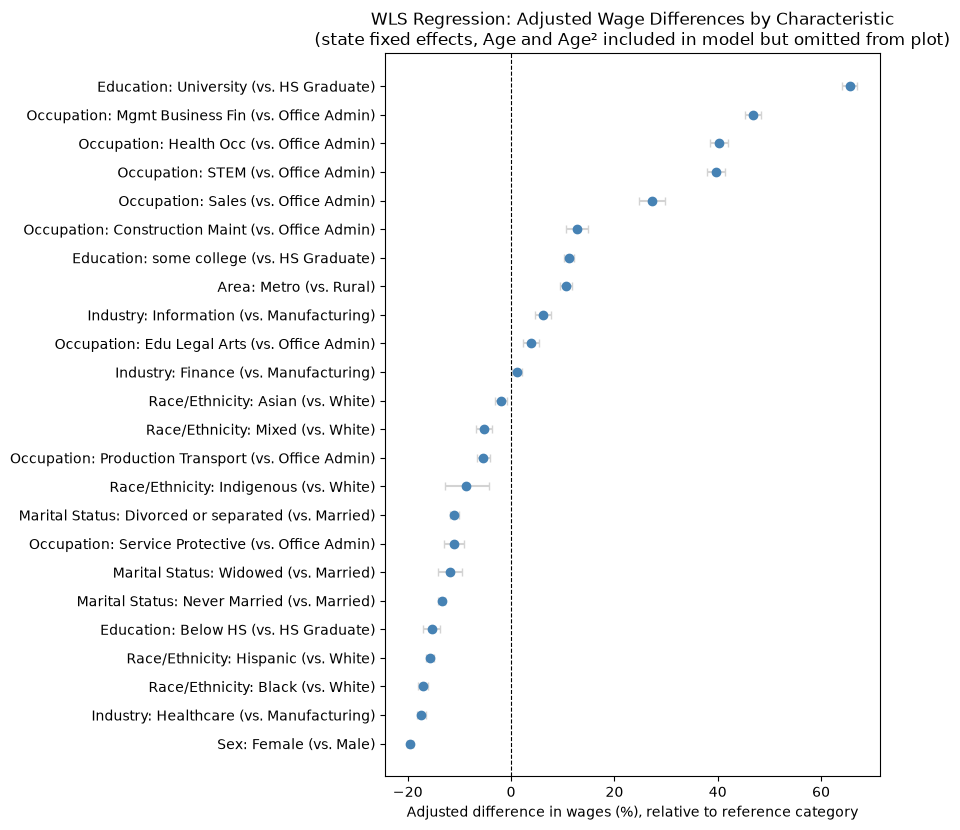

In [21]:
# --- Map raw variable names to nicer display names ---
var_display_names = {
    'Sex': 'Sex',
    'Education': 'Education',
    'Race_Eth': 'Race/Ethnicity',
    'Marital_Status': 'Marital Status',
    'Target_Industry': 'Industry',
    'OCC_Fine': 'Occupation',
    'Metro_Status': 'Area',
    'AGE': 'Age',
    'AGE2': 'Age squared',
}

def clean_label(raw_label):
    """Turn a patsy-style regression label into a readable string."""
    m = re.match(r"C\((\w+), Treatment\('([^']+)'\)\)\[T\.(.+)\]", raw_label)
    if m:
        var, ref, cat = m.groups()
        var_name = var_display_names.get(var, var)
        return f"{var_name}: {cat.replace('_', ' ')} (vs. {ref.replace('_', ' ')})"
    m2 = re.match(r"C\((\w+)\)\[T\.(.+)\]", raw_label)
    if m2:
        var, cat = m2.groups()
        return f"{var_display_names.get(var, var)}: {cat}"
    return var_display_names.get(raw_label, raw_label)

# --- Pull coefficients; drop state dummies and Age/Age² from the plot ---
coefs_all = wls_model.params.drop('Intercept')
conf_all = wls_model.conf_int().drop('Intercept')
conf_all.columns = ['lower', 'upper']

exclude = coefs_all.index.str.contains('State_Name') | coefs_all.index.isin(['AGE', 'AGE2'])
plot_coefs, plot_conf = coefs_all[~exclude], conf_all[~exclude]

plot_df = pd.DataFrame({
    'effect_pct': (np.exp(plot_coefs) - 1) * 100,
    'lower_pct': (np.exp(plot_conf['lower']) - 1) * 100,
    'upper_pct': (np.exp(plot_conf['upper']) - 1) * 100,
})
plot_df.index = [clean_label(i) for i in plot_df.index]
plot_df = plot_df.sort_values('effect_pct')

fig, ax = plt.subplots(figsize=(9, len(plot_df) * 0.35))
ax.errorbar(
    plot_df['effect_pct'], range(len(plot_df)),
    xerr=[plot_df['effect_pct'] - plot_df['lower_pct'], plot_df['upper_pct'] - plot_df['effect_pct']],
    fmt='o', color='steelblue', ecolor='lightgray', capsize=3
)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index)
ax.set_xlabel('Adjusted difference in wages (%), relative to reference category')
ax.set_title('WLS Regression: Adjusted Wage Differences by Characteristic\n'
             '(state fixed effects, Age and Age² included in model but omitted from plot)')
plt.tight_layout()
plt.show()

**Education has the largest single coefficient.**
The University coefficient (about 66%) is the largest in the model. The largest occupation coefficients are not far behind: compared with Office/Admin workers, Management/Business/Finance jobs pay about 47% more, and Health and STEM occupations about 40% more.

**Occupation differences are large.**
Occupation coefficients range from about −11% (Service/Protective) to +47% (Management/Business/Finance). Among industries, Finance (about 1%) and Information (about 6%) differ little from Manufacturing for workers with the same characteristics, including the same occupation group. Healthcare is the exception: within the same occupation group, it pays about 17% less than Manufacturing (see Section 8).

**Location is also associated with wages.**
Metro workers earn about 11% more than similar workers outside metro areas.

**The demographic differences are similar in size.**
Female (−19%), Black (−17%), and Hispanic (−16%) workers earn less by similar amounts. These are also close to the 15% lower wages for people who did not finish high school. Indigenous and Widowed have wider confidence intervals.
_This is probably because there are fewer people in these groups. Therefore, we should be careful not to over-interpret these results._

Age and Age² are not shown in the plot. They enter the model together, so their coefficients are in log points per year and per year², not percentage differences relative to a reference group like the other variables. See Section 7.3 for the age-earnings profile.

### 7.3 The Age-Earnings Profile

This graph shows the predicted wages for people aged 18–64. All other factors are kept the same: White, male, high school graduate, married, Manufacturing, Office/Admin occupation, and Rural.

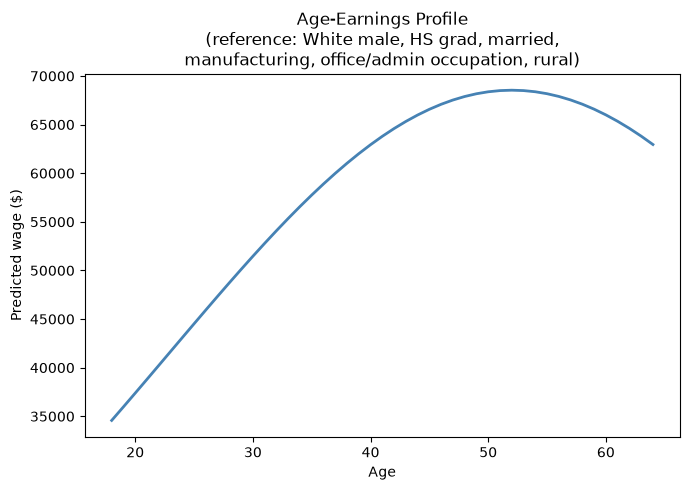

In [22]:
# --- Age-earnings profile (holding other covariates at reference levels) ---
age_range = np.arange(18, 65)

pred_df = pd.DataFrame({
    'AGE': age_range,
    'AGE2': age_range**2,
    'Sex': 'Male',
    'Education': 'HS_Graduate',
    'Race_Eth': 'White',
    'Marital_Status': 'Married',
    'Target_Industry': 'Manufacturing',
    'OCC_Fine': 'Office_Admin',          # <- reference category of OCC_Fine
    'Metro_Status': 'Rural',
    'State_Name': df_analysis['State_Name'].mode()[0],   # df_final -> df_analysis
})
pred_df['pred_wage'] = np.exp(wls_model.predict(pred_df))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pred_df['AGE'], pred_df['pred_wage'], color='steelblue', linewidth=2)
ax.set_xlabel('Age')
ax.set_ylabel('Predicted wage ($)')
ax.set_title('Age-Earnings Profile\n(reference: White male, HS grad, married,\nmanufacturing, office/admin occupation, rural)')
plt.tight_layout()
plt.show()

In [23]:
peak = pred_df.loc[pred_df['pred_wage'].idxmax()]
w18 = pred_df.loc[pred_df['AGE'] == 18, 'pred_wage'].iloc[0]
w64 = pred_df.loc[pred_df['AGE'] == 64, 'pred_wage'].iloc[0]

print((
    f"Predicted wages rise from about ${w18:,.0f} at age 18 to ${peak['pred_wage']:,.0f}"
    f" at age {int(peak['AGE'])}, then decline to ${w64:,.0f} at age 64 "
    f"({(w64 / peak['pred_wage'] - 1) * 100:.0f}% relative to the peak)."
))

Predicted wages rise from about $34,574 at age 18 to $68,537 at age 52, then decline to $62,950 at age 64 (-8% relative to the peak).


The result shows a classic **“hump-shaped”** pattern. 

This pattern is consistent with human capital theory. As workers get older, they gain more experience and skills, which can increase their wages. However, the effect of additional experience becomes smaller later in life, and wages may eventually decrease.

One important point is that this is a **cross-sectional analysis**. It compares different people of different ages in the same year. **It does not follow the same people throughout their careers**. Therefore, the graph shows how wages differ by age in this sample, not how one person's wage will change as they get older.

The reference worker is an illustrative combination of characteristics, so the dollar levels should not be read as typical wages. The shape of the curve is what matters here.

### 7.4 Robustness: household-clustered standard errors

The HC1 standard errors above allow for unequal variance but treat workers as independent. In the ACS, several workers can come from the same household, so I re-estimated the WLS model with standard errors clustered by household (SERIAL). The sample has 237,037 households for 270,135 workers (1.14 workers per household). Point estimates are identical by construction.

In [24]:
# --- Robustness: household-clustered standard errors ---
# IPUMS SERIAL identifies the household within this single-year sample.

wls_cl = fit_wls(main_formula, df_analysis,
                 cov_type='cluster', cov_kwds={'groups': df_analysis['SERIAL']})

n_clusters = df_analysis['SERIAL'].nunique()
print(f"Observations: {len(df_analysis):,} | households (clusters): {n_clusters:,} "
      f"| avg. workers per household: {len(df_analysis)/n_clusters:.2f}")

# Point estimates must be identical; only the standard errors change
assert np.allclose(wls_cl.params, wls_model.params)

# Industry coefficients: HC1 vs. household-clustered

ind_terms = industry_terms(wls_model)
cmp = pd.DataFrame({
    'coef': wls_model.params[ind_terms],
    'SE (HC1)': wls_model.bse[ind_terms],
    'SE (cluster)': wls_cl.bse[ind_terms],
    'p (HC1)': wls_model.pvalues[ind_terms],
    'p (cluster)': wls_cl.pvalues[ind_terms],
})
cmp['SE ratio'] = cmp['SE (cluster)'] / cmp['SE (HC1)']
cmp.index = [short_name(t) for t in ind_terms]
display(cmp.round(4))

# All non-state coefficients: how much do the SEs change overall?
non_state = [p for p in wls_model.params.index if 'State_Name' not in p and p != 'Intercept']
ratio = wls_cl.bse[non_state] / wls_model.bse[non_state]
print(f"\nSE ratio (cluster / HC1) across {len(non_state)} coefficients: "
      f"min {ratio.min():.2f}, median {ratio.median():.2f}, max {ratio.max():.2f}")





Observations: 270,135 | households (clusters): 237,037 | avg. workers per household: 1.14


,coef,SE (HC1),SE (cluster),p (HC1),p (cluster),SE ratio
Finance,0.0113,0.0049,0.0049,0.0204,0.0216,1.0095
Healthcare,-0.1911,0.0052,0.0052,0.0000,0.0000,1.0060
Information,0.0595,0.0073,0.0073,0.0000,0.0000,1.0098



SE ratio (cluster / HC1) across 26 coefficients: min 0.99, median 1.01, max 1.04


Across the 26 non-state coefficients, the clustered standard errors are between 0.99 and 1.04 times the HC1 standard errors (median 1.01). The three industry coefficients change by about 1% or less, so the conclusions do not change. The Finance coefficient (about 1%) remains significant at the 5% level (p = 0.022) but not at the 1% level; its 95% confidence interval is roughly 0.2% to 2.1%. The Finance advantage is therefore statistically detectable but economically small.

One limitation remains: ACS replicate weights (REPWTP in IPUMS) are not used, so the standard errors do not fully reflect the survey design.

# 8. What's Really Behind the Industry Wage Gap?

Section 7 controls for age, education, race, sex, marital status, occupation, metro status, and state at the same time.

However, looking at all these factors together gives us only one number. It does not tell us which factor is most important or whether different industries have different reasons for their wage differences.

In this section, we look at the industry wage gap one factor at a time.

We start with a simple question:

**How much of the wage gap between industries can be explained by differences in the workers**, and **how much of the gap remains after we control for these differences?**

             Raw gap (%)  Adjusted gap (%)
Finance             30.8               1.1
Healthcare         -10.9             -17.4
Information         36.9               6.1


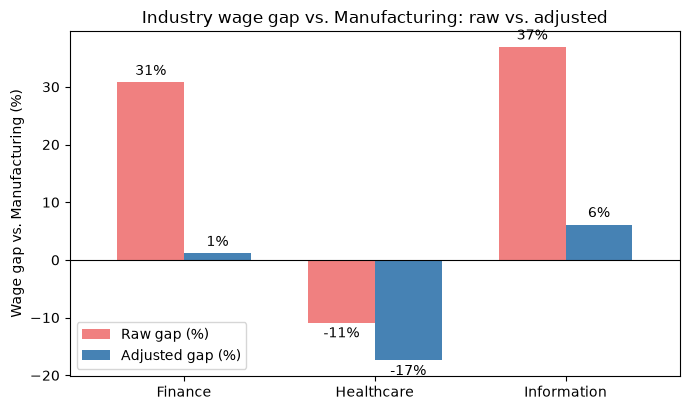

In [25]:
# Compare raw and adjusted wage gap

m_raw = fit_wls(BASE_FORMULA, df_analysis)
gap_table = pd.DataFrame({
    'Raw gap (%)': industry_gaps(m_raw),
    'Adjusted gap (%)': industry_gaps(wls_model),
})
print(gap_table.round(1))

# --- Visualize the results with a bar chart and saved as PNG for README ---
import os
os.makedirs('figures', exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 4.2))
gap_table.plot(kind='bar', ax=ax, color=['lightcoral', 'steelblue'], width=0.7)
ax.axhline(0, color='black', linewidth=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', padding=3)
ax.set_ylabel('Wage gap vs. Manufacturing (%)')
ax.set_title('Industry wage gap vs. Manufacturing: raw vs. adjusted')
ax.legend(title='')
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig('figures/industry_gap.png', dpi=200)



Finance and Information are approximately 31–37% higher than Manufacturing, while Healthcare is about 11% lower (based on geometric means).
After controlling for worker characteristics and occupation, the Finance gap almost disappears (about 1%), the Information gap shrinks to about 6%, and the Healthcare gap becomes larger (about −17%).

So differences in worker characteristics and occupation account for over 95% of the raw Finance gap and more than 80% of the raw Information gap. For Healthcare, composition works the other way: Healthcare workers are more likely than Manufacturing workers to have a university degree and to hold well-paid health occupations, so the raw numbers understate the gap between similar workers.

In the rest of this section, we look at which factors (education, race, sex, or occupation) help account for these differences.

### 8.1 Which characteristic actually explains the gap?

The full model controls for everything at the same time, so we cannot tell whether education, race, or sex is the most important factor.

To find out, I add the controls one group at a time and see how the industry coefficient changes:

No controls → Education → Race → Sex → Occupation

If the industry coefficient moves a lot toward zero, that group of variables explains a large part of the wage gap. If it changes only a little, it does not explain much of the gap.

             No controls  + Education  + Race  + Sex  + Occupation  Full model
Finance             30.8          6.2     7.1   13.8           0.3         1.1
Healthcare         -10.9        -20.6   -18.6   -9.2         -17.4       -17.4
Information         36.9         10.2    11.0   13.6           7.4         6.1


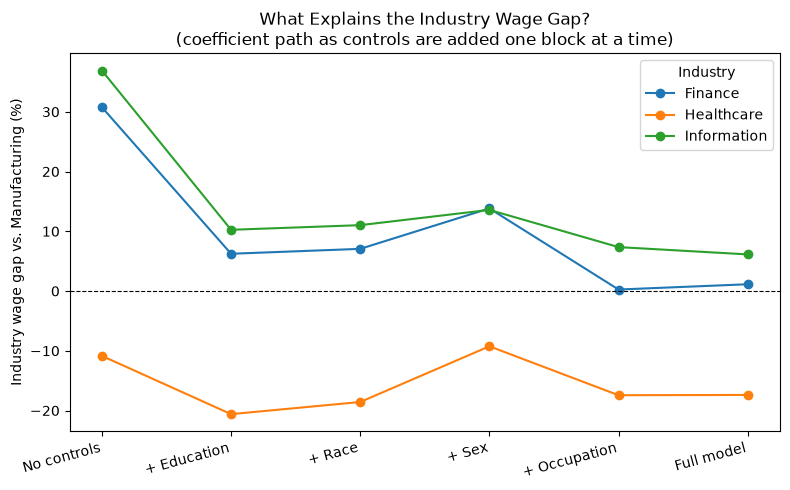

In [26]:
path_order = ['Education', 'Race', 'Sex', 'Occupation']   

path_models = {'No controls': fit_wls(BASE_FORMULA, df_analysis)}
for k in range(1, len(path_order) + 1):
    path_models['+ ' + path_order[k - 1]] = fit_wls(formula_with(path_order[:k]), df_analysis)
path_models['Full model'] = wls_model

industry_path = pd.DataFrame({label: industry_gaps(m) for label, m in path_models.items()})
print(industry_path.round(1))


# --- Visualize the results with a line chart ---
fig, ax = plt.subplots(figsize=(8, 5))
for industry in industry_path.index:
    ax.plot(industry_path.columns, industry_path.loc[industry], marker='o', label=industry)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_ylabel('Industry wage gap vs. Manufacturing (%)')
ax.set_title('What Explains the Industry Wage Gap?\n(coefficient path as controls are added one block at a time)')
ax.legend(title='Industry')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

| | No controls | + Education | + Race | + Sex | + Occupation | Full model |
|---|---|---|---|---|---|---|
| **Finance** | 30.8% | 6.2% | 7.1% | 13.8% | 0.3% | 1.1% |
| **Healthcare** | -10.9% | -20.6% | -18.6% | -9.2% | -17.4% | -17.4% |
| **Information** | 36.9% | 10.2% | 11.0% | 13.6% | 7.4% | 6.1% |

**Finance and Information: education and occupation account for most of the raw gap.**
Adding education alone reduces the gap from about 31–37% to 6–10%. Adding race changes it very little. Adding sex raises it again (Finance: 7.1% → 13.8%; Information: 11.0% → 13.6%). Finance and Information have higher shares of women than Manufacturing, and women earn less in this sample, so sex composition was pulling their average wages down. Adding occupation then lowers the Finance gap from 13.8% to 0.3% and the Information gap from 13.6% to 7.4%. In the full model, Finance is about 1% and Information about 6%. Education and occupation are closely related (workers with degrees are more likely to hold management, business, and STEM jobs), so how much credit each gets depends on the order. The averaged results below address this.

**Healthcare: composition effects work in opposite directions.**
Adding education makes the gap larger (−10.9% → −20.6%), because Healthcare workers are more educated than Manufacturing workers (50% vs. 37% hold a university degree). Adding sex narrows it (−18.6% → −9.2%), because Healthcare is about 74% female. Adding occupation widens it again (−9.2% → −17.4%), because about half of Healthcare workers hold health occupations, compared with 0.3% in Manufacturing. The full model gives −17.4%. Compared with Manufacturing workers with the same education, sex, race, and occupation, Healthcare workers earn about 17% less.

*Caution.* Almost no Manufacturing workers hold health occupations, so the Healthcare coefficient rests mainly on non-health occupations (overlap shares are in Appendix A).

**Race does not have much effect in any of the three industries.** Adding race changes the gap by about 2 points or less.

Note: Each step shows the change after the earlier blocks are already included, so the size of a step depends on the order. 

The "Full model" column also adds Age, marital status, metro status, and state all at once, so the last step from "+ Occupation" to "Full model" is small: Finance 0.3 → 1.1, Information 7.4 → 6.1, Healthcare unchanged.

#### Shapley-style decomposition

The step-by-step results in 8.1 depend on the order in which controls are added. Here I average each block's contribution over all 120 possible orders of five blocks: education, race, sex, occupation, and other controls (age, marital status, metro status, and state). This is a Shapley-style decomposition. Because the fifth block contains all remaining controls, the contributions sum exactly to the difference between the full-model gap and the raw gap.

In [27]:
cache = {}   # frozenset(blocks used) -> industry gaps (%)
for r in range(len(BLOCK_TERMS) + 1):
    for subset in combinations(BLOCK_TERMS, r):
        cache[frozenset(subset)] = industry_gaps(fit_wls(formula_with(subset), df_analysis))

contrib = {b: 0 for b in BLOCK_TERMS}
orders = list(permutations(BLOCK_TERMS))
for order in orders:
    seen = frozenset()
    for b in order:
        contrib[b] = contrib[b] + (cache[seen | {b}] - cache[seen])
        seen = seen | {b}
shapley = pd.DataFrame({b: v / len(orders) for b, v in contrib.items()})

# Check: contributions sum to (full-model gap) - (no-controls gap)
full_gaps = industry_gaps(wls_model)
assert np.allclose(shapley.sum(axis=1), full_gaps - cache[frozenset()])
print(shapley.round(1))

             Education  Race  Sex  Occupation  Other controls
Finance          -12.7  -0.7  5.8       -20.1            -1.9
Healthcare        -5.3   1.5  8.2       -10.8            -0.1
Information      -13.7  -1.1  1.7       -14.0            -3.7


In Finance and Information, occupation and education are the two largest contributions, and both lower the gap (Finance: −20.1 and −12.7 points; Information: −14.0 and −13.7 points). Sex raises the gap (+5.8 for Finance, +1.7 for Information), and race is close to zero. The other controls matter little, except for Information (−3.7 points). In Healthcare, sex narrows the gap (+8.2 points), while occupation (−10.8) and education (−5.3) widen it.

Once the order is averaged out, occupation is the largest (or tied-largest) contributor in all three industries, while education looked largest in the single order used above. Because education and occupation are closely related, their combined contribution is more reliable than either one alone (Finance −33, Information −28, Healthcare −16 points).

**How to read the occupation-adjusted gap.** Occupation is not only a characteristic of the worker: which occupations exist in an industry is part of what the industry is (Healthcare employs health practitioners; Manufacturing employs production workers). Adding occupation therefore changes the question from "how do industries pay workers like these?" to "how do industries pay workers *in the same occupation group*?" Gaps after the "+ Occupation" step are within-occupation differences, and the part of the raw gap that comes from the occupation mix itself is absorbed by the occupation contribution. Education, race, and sex are mostly determined before a worker joins an industry, whereas occupation is partly shaped by the industry.

### 8.2 Confirming the composition story directly

The decomposition above is inferred indirectly, from how coefficients move. It's worth checking the underlying workforce composition directly rather than taking the regression's word for it.

In [28]:
# --- Directly examine the gender and education composition of each industry ---

def weighted_crosstab(df, row, col, weight='PERWT'):
    """Row-normalized (%) crosstab, weighted by PERWT."""
    ct = pd.crosstab(df[row], df[col], values=df[weight],
                     aggfunc='sum', normalize='index') * 100
    assert np.allclose(ct.sum(axis=1), 100)   # each row must sum to 100%
    return ct

comp_sex  = weighted_crosstab(df_analysis, 'Target_Industry', 'Sex')
comp_edu  = weighted_crosstab(df_analysis, 'Target_Industry', 'Education')
comp_race = weighted_crosstab(df_analysis, 'Target_Industry', 'Race_Eth')
comp_occ  = weighted_crosstab(df_analysis, 'Target_Industry', 'OCC_Fine')

print("Sex composition by industry (%, weighted):")
print(comp_sex.round(1))
print("\nEducation composition by industry (%, weighted):")
print(comp_edu.round(1))
print("\nRace composition by industry (%, weighted):")
print(comp_race.round(1))
print("\nOccupation composition by industry (%, weighted):")
display(comp_occ.round(1).T)

Sex composition by industry (%, weighted):
Sex              Female  Male
Target_Industry              
Finance            53.0  47.0
Healthcare         73.8  26.2
Information        36.8  63.2
Manufacturing      28.5  71.5

Education composition by industry (%, weighted):
Education        Below_HS  HS_Graduate  University  some_college
Target_Industry                                                 
Finance               0.7         17.3        62.8          19.2
Healthcare            2.4         23.9        50.0          23.7
Information           1.1         17.6        64.8          16.5
Manufacturing         6.6         37.1        37.1          19.2

Race composition by industry (%, weighted):
Race_Eth         Asian  Black  Hispanic  Indigenous  Mixed  White
Target_Industry                                                  
Finance           10.3   11.2      13.5         0.2    3.9   61.0
Healthcare         9.1   16.9      18.0         0.4    3.9   51.6
Information       12.9   10.

Target_Industry,Finance,Healthcare,Information,Manufacturing
OCC_Fine,,,,
Construction_Maint,0.2,0.8,7.8,6.6
Edu_Legal_Arts,2.7,9.4,19.8,1.7
Health_Occ,1.4,52.2,0.2,0.3
Mgmt_Business_Fin,50.7,13.9,29.3,21.0
Office_Admin,18.3,12.5,10.4,7.0
Production_Transport,0.6,1.3,1.9,40.9
STEM,12.9,4.0,22.0,17.6
Sales,12.3,0.4,7.5,3.6
Service_Protective,0.9,5.5,1.1,1.3


Composition shares in this section are weighted sample shares.

The composition numbers support our results:

**Sex**: Healthcare is 73.8% female, while Manufacturing is 28.5% female, the largest gap among the four industries. Finance sits in between (53.0% female, 24.5 points above Manufacturing), and Information is closest to Manufacturing (36.8% female, 8.3 points above). This graded pattern matches the regression results. In the step-by-step path in 8.1, adding sex moves the estimated industry gap by +9.3 points for Healthcare, +6.7 for Finance, and +2.5 for Information. Averaging over all possible orderings gives +8.2, +5.8, and +1.7. Under both approaches, the industry ranking is the same: the larger the difference in female share from Manufacturing, the more the industry gap changes when sex is controlled for. For Finance, sex is the third-largest contribution under both approaches (after education and occupation in the step-by-step path, and after occupation and education when averaged).

**Education**: 62.8% of Finance workers and 64.8% of Information workers have a university degree, compared with 37.1% in Manufacturing. Healthcare is in the middle, with 50.0% having a university degree. This helps explain why education is important for Finance and Information, and still an important factor for Healthcare too.

**Occupation**: About half of Healthcare workers (52.2%) hold health occupations, compared with 0.2–1.4% in the other three industries. About half of Finance workers (50.7%) hold management, business, or financial occupations, compared with 21.0% in Manufacturing. In Manufacturing, 40.9% hold production or transportation occupations, compared with 0.6–1.9% elsewhere. In "Information", only 22.0% hold STEM occupations, and 19.8% hold education, legal, arts, or media occupations. This is because this group is NAICS sector 51 (Information), which includes publishing, broadcasting, and telecommunications, and excludes computer systems design.

**Race**: Race varies less across the four industries than sex or education. The share of White workers ranges from 51.6% in Healthcare to 61.0% in Finance, a difference of about 9 percentage points. In comparison, the difference is 45.3 points for sex and 27.7 points for education. Healthcare stands out somewhat: 16.9% of its workers are Black, compared with 9.4% in Manufacturing. This is the one place where race moves the industry gap noticeably in 8.1, and it is still small compared with education, occupation, and sex.

For a variable to account for a wage gap between industries, two things are needed:
1. it is associated with wages, and
2. it is distributed differently across the industries.

In these four industries, race is associated with wages, but its share does not change much across industries. Sex and education, on the other hand, both are associated with wages and vary a lot across industries.

Overall, sex explains more of the wage gap where the sex composition is very different. Education explains more where education levels are very different. Race explains very little because its composition is similar across these four industries, even though race/ethnicity is strongly associated with individual wages.

### 8.3 Takeaways

The wage differences between industries do not line up with just one characteristic. Much of the gap is accounted for by differences in **who works in each industry and what jobs they hold**, especially education, occupation, and sex.

1. **Finance and Information:**
   Finance and Information appear to pay much more than Manufacturing (31% and 37%). Most of this difference reflects the education and occupations of their workers: they employ many more university graduates and more people in management, business, finance, and STEM jobs. After controlling for these differences, the gap is about **1% for Finance** and **6% for Information**. Sex works in the opposite direction, because these industries employ more women than Manufacturing.

2. **Healthcare:**
   Healthcare appears to pay about 11% less than Manufacturing, but this understates the gap between similar workers. Healthcare employs more university graduates and more workers in well-paid health occupations than Manufacturing, which raises its raw average, while its mostly female workforce lowers it (women earn less in this sample). After controlling for all these differences, Healthcare pays about **17% less** than Manufacturing. Because almost no Manufacturing workers hold health occupations, this estimate relies mainly on comparisons within non-health occupations.

3. **Race:**
   Race does not explain much of the wage differences between industries (about 2 points or less). Race/ethnicity is associated with individual workers' wages, but the racial composition of the four industries is fairly similar.

4. **Sensitivity:**
   These results depend on how occupations are grouped. With the four occupation groups used in the group project, the adjusted gaps are 8.6% (Finance), −4.5% (Healthcare), and 10.5% (Information) (see Appendix). The Healthcare result is the most sensitive.

**Overall:**
**Most of the apparent Finance and Information advantage reflects who works in these industries and what jobs they hold, mainly education and occupation, while this composition hides part of the Healthcare pay gap. Race/ethnicity accounts for very little of the differences between industries. All results are adjusted associations, not causal effects.**


### Appendix: Sensitivity to the occupation classification

The group project used four occupation groups, including a residual group (`Service_Others`) that also contains health practitioners, teachers, lawyers, and sales workers. My main specification uses nine groups based on Census 2018 occupation codes. To see how much the industry gaps depend on this choice, I re-estimate the main WLS model while changing only the occupation control: none, the 4 group-project groups, the 9 main groups, 22 SOC major groups, and 504 detailed occupation codes (absorbed as fixed effects).

The right panel shows how many workers can be compared with Manufacturing at all: for each industry, the weighted share of workers whose occupation has at least 5% Manufacturing workers among the industry's and Manufacturing's workers in that occupation.

In [29]:
# --- Occupation ladder: build SOC major groups from Census 2018 OCC codes ---
lad = df_analysis.join(df_final_four[['OCC']])     # OCC was dropped from df_analysis in Section 5
lad['OCC'] = lad['OCC'].astype(int)

SOC_LOWER_BOUNDS = [   # lower bound of each SOC major group (bounds sit in unused gaps between groups)
    (10,   'Management'),                       # SOC 11
    (500,  'Business_Financial'),               # 13
    (1005, 'Computer_Math'),                    # 15
    (1305, 'Architecture_Engineering'),         # 17
    (1600, 'Life_Physical_Social_Science'),     # 19
    (2000, 'Community_Social_Service'),         # 21
    (2100, 'Legal'),                            # 23
    (2200, 'Education_Library'),                # 25
    (2600, 'Arts_Media_Sports'),                # 27
    (3000, 'Healthcare_Practitioners'),         # 29
    (3600, 'Healthcare_Support'),               # 31
    (3700, 'Protective_Service'),               # 33
    (4000, 'Food_Prep_Serving'),                # 35
    (4200, 'Building_Grounds'),                 # 37
    (4260, 'Personal_Care_Service'),            # 39
    (4700, 'Sales'),                            # 41
    (5000, 'Office_Admin_Support'),             # 43
    (6000, 'Farming_Fishing_Forestry'),         # 45
    (6200, 'Construction_Extraction'),          # 47
    (7000, 'Install_Maint_Repair'),             # 49
    (7700, 'Production'),                       # 51
    (9000, 'Transportation_Moving'),            # 53
]
_starts = np.array([s for s, _ in SOC_LOWER_BOUNDS])
_names = np.array([nm for _, nm in SOC_LOWER_BOUNDS])
_idx = np.searchsorted(_starts, lad['OCC'].to_numpy(), side='right') - 1
assert (_idx >= 0).all(), "found an OCC code below the first lower bound"
lad['OCC_SOC'] = _names[_idx]

# Check: every SOC group must sit inside exactly one of the 9 groups (the ladder is nested)
ct = pd.crosstab(lad['OCC_SOC'], lad['OCC_Fine'])
assert (ct.gt(0).sum(axis=1) == 1).all(), ct[ct.gt(0).sum(axis=1) > 1]

print(lad[['OCC_Group', 'OCC_Fine', 'OCC_SOC', 'OCC']].nunique())
print("Detailed OCC cells with fewer than 10 workers:", (lad['OCC'].value_counts() < 10).sum())

OCC_Group      4
OCC_Fine       9
OCC_SOC       22
OCC          504
dtype: int64
Detailed OCC cells with fewer than 10 workers: 68


In [30]:
from patsy import dmatrices
import statsmodels.api as sm

def fit_wls_absorb(formula, data, absorb):
    """WLS (PERWT, HC1) with one fixed effect `absorb` removed by weighted demeaning (FWL).
    Same coefficients/SEs as adding C(absorb) to the formula, without building hundreds of dummies."""
    y, X = dmatrices(formula, data, return_type='dataframe')
    X = X.drop(columns='Intercept')
    w = data.loc[y.index, 'PERWT'].to_numpy()
    codes, uniques = pd.factorize(data.loc[y.index, absorb])
    sw = np.bincount(codes, weights=w)
    def demean(a):
        return a - (np.bincount(codes, weights=w * a) / sw)[codes]
    y_dm = demean(y.iloc[:, 0].to_numpy())
    X_dm = pd.DataFrame({c: demean(X[c].to_numpy()) for c in X.columns}, index=y.index)
    res = sm.WLS(y_dm, X_dm, weights=w).fit(cov_type='HC1')
    n_obs, k, G = len(y), X.shape[1], len(uniques)
    res.dof_adj = (n_obs - k) / (n_obs - k - G)    # HC1 small-sample factor for the absorbed G dummies
    return res

def industry_gap_ci(model, z=1.96):
    """Industry gap vs. Manufacturing in % with 95% CI."""
    terms = industry_terms(model)
    b = model.params[terms]
    se = model.bse[terms] * np.sqrt(getattr(model, 'dof_adj', 1.0))
    out = pd.DataFrame({'gap': (np.exp(b) - 1) * 100,
                        'lo':  (np.exp(b - z * se) - 1) * 100,
                        'hi':  (np.exp(b + z * se) - 1) * 100})
    out.index = [short_name(t) for t in terms]
    return out

def overlap_share(data, occ_col, ref='Manufacturing', min_share=0.05):
    """For each industry T: weighted share (%) of T workers whose occupation cell has at least
    `min_share` Manufacturing workers among (T + Manufacturing) workers in that cell."""
    W = data.pivot_table(index=occ_col, columns='Target_Industry', values='PERWT',
                         aggfunc='sum', fill_value=0)
    out = {}
    for t in W.columns.drop(ref):
        p_ref = W[ref] / (W[t] + W[ref])
        out[t] = W.loc[p_ref >= min_share, t].sum() / W[t].sum() * 100
    return pd.Series(out)

# Main formula without the occupation block
formula_no_occ = main_formula.replace(BLOCK_TERMS['Occupation'] + " + ", "")
assert formula_no_occ != main_formula and 'OCC_Fine' not in formula_no_occ

LADDER_LEVELS = {                 # label -> occupation column (None = no occupation control)
    'ALL controls,\nno occupation': None,
    '4 groups':               'OCC_Group',
    '9 groups\n(main)':       'OCC_Fine',
    'SOC major\ngroups':      'OCC_SOC',
    'Detailed\nOCC':          'OCC',
}

gap_rows, ov_rows = [], []
for label, col in LADDER_LEVELS.items():
    if col is None:
        m, n_cat = fit_wls(formula_no_occ, lad), 0
        ov = pd.Series(100.0, index=['Finance', 'Healthcare', 'Information'])
    else:
        m, n_cat = fit_wls_absorb(formula_no_occ, lad, col), lad[col].nunique()
        ov = overlap_share(lad, col)
    gap_rows.append(industry_gap_ci(m).assign(level=label, n_cat=n_cat).rename_axis('industry').reset_index())
    ov_rows.append(ov.rename(label))
ladder = pd.concat(gap_rows, ignore_index=True)
overlap = pd.DataFrame(ov_rows)

# Sanity check: absorbing the 9 groups must reproduce the main model's industry coefficients and SEs
m9 = fit_wls_absorb(formula_no_occ, lad, 'OCC_Fine')
t9, t_main = industry_terms(m9), industry_terms(wls_model)
assert np.allclose(m9.params[t9].values, wls_model.params[t_main].values, atol=1e-8)
assert np.allclose(m9.bse[t9].values * np.sqrt(m9.dof_adj), wls_model.bse[t_main].values, rtol=1e-6)

flat = lambda s: s.replace('\n', ' ')
print(ladder.pivot(index='level', columns='industry', values='gap')
            .reindex(list(LADDER_LEVELS)).rename(index=flat).round(1))
print(overlap.rename(index=flat).round(1))

industry                     Finance  Healthcare  Information
level                                                        
ALL controls, no occupation     11.3        -9.7         10.4
4 groups                         8.6        -4.5         10.5
9 groups (main)                  1.1       -17.4          6.1
SOC major groups                 1.2       -17.1          5.2
Detailed OCC                     0.8       -15.4          5.9
                             Finance  Healthcare  Information
ALL controls, no occupation    100.0       100.0        100.0
4 groups                       100.0       100.0        100.0
9 groups (main)                100.0        47.8        100.0
SOC major groups               100.0        40.5        100.0
Detailed OCC                    66.3        26.2         82.2


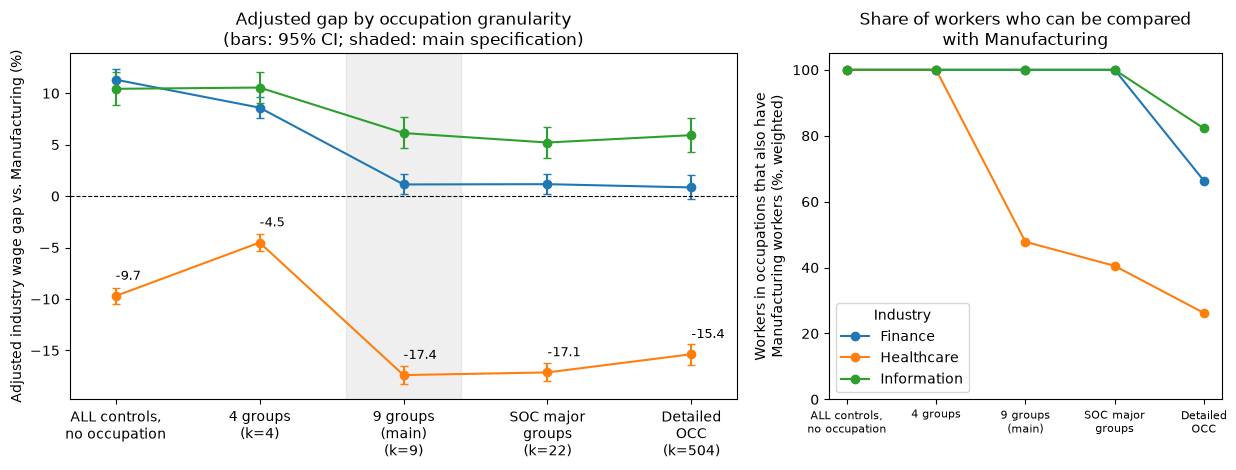

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1.7, 1]})
x = np.arange(len(LADDER_LEVELS))
xt = [f"{lab}\n(k={ladder.loc[ladder['level'] == lab, 'n_cat'].iloc[0]})" if col else lab
      for lab, col in LADDER_LEVELS.items()]

for ind in ['Finance', 'Healthcare', 'Information']:
    d = ladder[ladder['industry'] == ind].set_index('level').reindex(list(LADDER_LEVELS))
    ax1.errorbar(x, d['gap'], yerr=[d['gap'] - d['lo'], d['hi'] - d['gap']],
                 marker='o', capsize=3, label=ind)
    if ind == 'Healthcare':   # label only the focus industry to keep the chart readable
        for xi, v in zip(x, d['gap']):
            ax1.annotate(f"{v:.1f}", (xi, v), textcoords='offset points',
                         xytext=(0, 14), ha='left', va='center', fontsize=9)
ax1.margins(x=0.08)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax1.axvspan(1.6, 2.4, color='grey', alpha=0.12)          # main specification
ax1.set_xticks(x, xt)
ax1.set_ylabel('Adjusted industry wage gap vs. Manufacturing (%)')
ax1.set_title('Adjusted gap by occupation granularity\n(bars: 95% CI; shaded: main specification)')

for ind in overlap.columns:
    ax2.plot(x, overlap[ind].values, marker='o', label=ind)
ax2.set_xticks(x, list(LADDER_LEVELS), fontsize=8)
ax2.set_ylim(0, 105)
ax2.set_ylabel('Workers in occupations that also have\nManufacturing workers (%, weighted)')
ax2.set_title('Share of workers who can be compared\nwith Manufacturing')
ax2.legend(title='Industry', loc='lower left')

plt.tight_layout()
plt.show()

**Finance and Information.** With no occupation control the gaps are about 11% and 10%. With nine or more occupation groups they fall to about 1% (Finance, 0.8–1.2%) and 5–6% (Information) and barely change between 9 groups, SOC groups, and detailed codes. The four-group version (8.6% and 10.5%) is much closer to the no-control result.

**Healthcare.** The gap is −9.7% with no occupation control, −4.5% with the four group-project groups, and between −15.4% and −17.4% with nine or more groups. The four-group result is the outlier: physicians, nurses, and other health workers fall into the residual reference group (`Service_Others`), which probably makes Healthcare look less different from the reference.

**Comparability.** With nine groups, only 47.8% of Healthcare workers are in occupations that also have Manufacturing workers (40.5% with SOC groups, 26.2% with detailed codes). The Healthcare estimate therefore rests mainly on workers in non-health occupations.

**Conclusion.** The Finance and Information results hold once occupations are grouped at least as finely as in the main specification. The Healthcare gap is large (−15% to −17%) with finer groups, but it depends on the classification and on a limited share of comparable workers, so I read it as "Healthcare pays less than Manufacturing within comparable non-health occupations," not as a precise number.

**Healthcare definition.** "Healthcare" is NAICS 62 (Health Care and Social Assistance). Excluding social assistance (NAICS 624, about 13% of Healthcare workers), the raw gap is −5.7% instead of −10.9% and the adjusted gap is −13.9% instead of −17.4%. Finance (1.2%) and Information (4.8%) move by 1.3 points or less. The adjusted gap is still clearly negative and still larger than the raw gap, so the main conclusion is unchanged, but part of the Healthcare gap comes from social assistance.

In [32]:
# --- Sensitivity: exclude social assistance (NAICS 624) from Healthcare ---
ind3_a = (df_final_four['INDNAICS'].astype(str).str.strip().str[:3]
          .loc[df_analysis.index])
is_hc = df_final_four.loc[df_analysis.index, 'Target_Industry'] == 'Healthcare'

# Composition of Healthcare in the analysis sample (unweighted)
print(ind3_a[is_hc].value_counts(normalize=True).round(3))

no624 = df_analysis[ind3_a != '624']

hc_check = pd.DataFrame({
    'NAICS 62 (main)': [industry_gaps(fit_wls(BASE_FORMULA, df_analysis))['Healthcare'],
                        industry_gaps(fit_wls(main_formula, df_analysis))['Healthcare']],
    'Excl. NAICS 624': [industry_gaps(fit_wls(BASE_FORMULA, no624))['Healthcare'],
                        industry_gaps(fit_wls(main_formula, no624))['Healthcare']],
}, index=['Raw gap (%)', 'Adjusted gap (%)']).round(1)
display(hc_check)

INDNAICS
622    0.395
621    0.376
624    0.132
623    0.097
Name: proportion, dtype: float64


,NAICS 62 (main),Excl. NAICS 624
Raw gap (%),-10.9,-5.7
Adjusted gap (%),-17.4,-13.9
